In [4]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import json
import csv
import os
import scipy as sp
import torch

In [5]:
os.getcwd()

'C:\\Users\\dvu29\\Documents\\ADMM_MTGP\\sand_box'

In [6]:
# true data
# test_data = "Set1.mat"
# prevent the res too small = 0
EPS_RES = 1e-12   # for residuals
EPS_REL = 1e-14   # for relative error

data_path = r"..//data//10 Agents//p5//Set1.mat" 

In [7]:
data = sp.io.loadmat(data_path)
#extract data

gamma_list = data["Phi"][0] ## hessian for each agent local function ## they are symetric

theta_list = [np.asarray(t).reshape(-1) for t in data["theta"][0]] ## theta of the f_i(x_i) = (x_i-theta_i) @ phi @ (x_i-theta_i)

In [15]:
data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'J_solver', 'Phi', 'options', 'solution', 'theta', '__function_workspace__'])

In [70]:
exact_obj = data['J_solver'][0]
exact_obj.shape

(1,)

In [71]:
exact_obj

array([1.85020987])

In [112]:
sogp_output_path = r"..//results//sogp_admm_results_summary.jsonl"
mtgp_output_path = r"..//results//mtgp_admm_results_summary.jsonl"
vanilla_output_path = r"..//results//vanilla_admm_results_summary.jsonl"

In [113]:
# read_csv

sogp_data = pd.read_json(sogp_output_path, lines=True)
mtgp_data = pd.read_json(mtgp_output_path, lines=True)
vanilla_data = pd.read_json(vanilla_output_path, lines=True)

In [114]:
sogp_data["other_stats"][10]

[{'g_var': [0.11955170333385401,
   0.127638429403305,
   0.13326907157897902,
   0.131308078765869,
   0.117016740143299],
  'var_max': 0.13326907157897902,
  'psi_k': 0.1415643359375,
  'do_query': False},
 {'g_var': [0.126662209630012,
   0.11791019141674002,
   0.12282633781433101,
   0.11876170337200101,
   0.11881798505783],
  'var_max': 0.126662209630012,
  'psi_k': 0.135735927734375,
  'do_query': False},
 {'g_var': [0.14573700726032202,
   0.124164119362831,
   0.141561895608901,
   0.12547542154788902,
   0.145252406597137],
  'var_max': 0.14573700726032202,
  'psi_k': 0.1364344921875,
  'do_query': True},
 {'g_var': [0.12576667964458402,
   0.128508046269416,
   0.13048730790615,
   0.129485443234443,
   0.113540217280387],
  'var_max': 0.13048730790615,
  'psi_k': 0.125538671875,
  'do_query': True},
 {'g_var': [0.130101144313812,
   0.129261195659637,
   0.12271098792552901,
   0.125827461481094,
   0.12498346716165501],
  'var_max': 0.130101144313812,
  'psi_k': 0.1332082

In [115]:
stats = sogp_data["other_stats"]

In [116]:
stats[5]

[{'g_var': [0.7797136306762691,
   0.7867435216903681,
   0.8524540066719051,
   0.86404013633728,
   0.7671244144439691],
  'var_max': 0.86404013633728,
  'psi_k': 0.43202006816864,
  'do_query': True},
 {'g_var': [0.8284663558006281,
   0.773197591304779,
   0.825405836105346,
   0.781243979930877,
   0.7725918889045711],
  'var_max': 0.8284663558006281,
  'psi_k': 0.41423317790031405,
  'do_query': True},
 {'g_var': [0.832730054855346,
   0.800355553627014,
   0.8239141702651971,
   0.80288678407669,
   0.8279287815093991],
  'var_max': 0.832730054855346,
  'psi_k': 0.416365027427673,
  'do_query': True},
 {'g_var': [0.7256804108619691,
   0.7390202879905701,
   0.7648175954818721,
   0.7662272453308101,
   0.712873697280883],
  'var_max': 0.7662272453308101,
  'psi_k': 0.38311362266540505,
  'do_query': True},
 {'g_var': [0.800028085708618,
   0.8130384087562561,
   0.8071515560150141,
   0.7949890494346611,
   0.8121597170829771],
  'var_max': 0.8130384087562561,
  'psi_k': 0.4065

In [117]:
# SOGP
primal_residual_sogp = sogp_data["primal_residual"]
dual_residual_sogp = sogp_data["dual_residual"]
obj_val_sogp = sogp_data["obj_val"]

# MTGP
primal_residual_mtgp = mtgp_data["primal_residual"]
dual_residual_mtgp = mtgp_data["dual_residual"]
obj_val_mtgp = mtgp_data["obj_val"]

# vanilla

primal_residual_vanilla = vanilla_data["primal_residual"]
dual_residual_vanilla = vanilla_data["dual_residual"]
obj_val_vanilla = vanilla_data["obj_val"]

In [118]:
sogp_data

,iteration,primal_residual,dual_residual,obj_val,comm_per_iter,grads_error_per_iter,other_stats
0,0,0.342034,11.955591,14.775162,10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
1,1,0.081630,7.811456,8.085232,10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
2,2,0.017326,5.194689,5.040678,10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
3,3,0.018534,3.542359,3.574743,10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
4,4,0.017075,2.489902,2.832352,10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
5,5,0.013243,1.807118,2.435719,10,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[{'g_var': [0.7797136306762691, 0.786743521690..."
6,6,0.028729,1.360310,2.305461,4,"[0.143591360767083, 0.173371581765234, 0.0, 0....","[{'g_var': [0.30904898047447205, 0.32195535302..."
7,7,0.011867,1.101900,2.041682,6,"[0.0, 0.0, 0.13270123382954502, 0.072257393856...","[{'g_var': [0.31337544322013805, 0.32863190770..."
8,8,0.011097,0.941048,2.017989,0,"[0.099641773171303, 0.13489591626324401, 0.212...","[{'g_var': [0.11772508919239001, 0.12422648817..."
9,9,0.004648,0.834859,1.967315,0,"[0.12223665674753902, 0.148375911495851, 0.295...","[{'g_var': [0.118757352232933, 0.1261469423770..."


## SOGP - ADMM

In [119]:
# relative error
sogp_rel_err = np.abs(obj_val_sogp - exact_obj)/np.abs(exact_obj)

In [120]:
#plot the relative error
x_axis_sogp = list(range(len(obj_val_sogp)))
x_axis_sogp

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43]

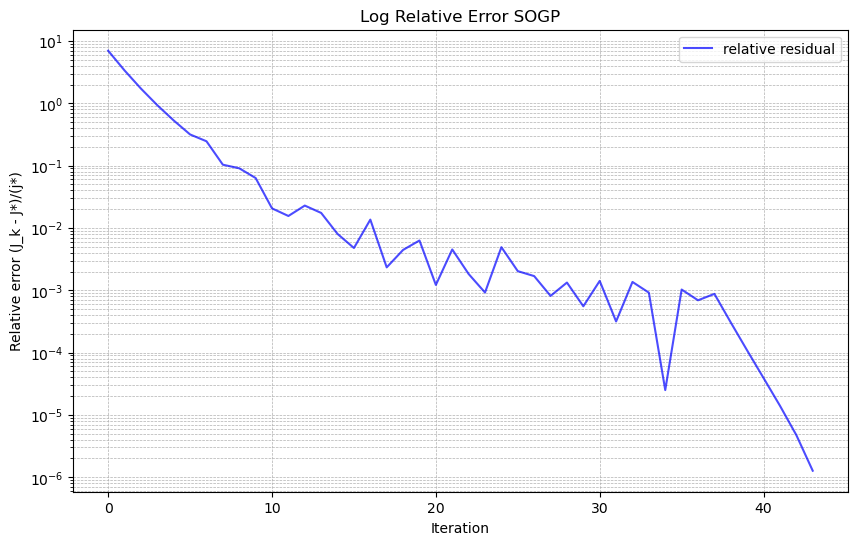

In [121]:
## Relative error

plt.figure(figsize=(10,6))
# plt.scatter(x_axis, log_rel_res, color="blue", alpha=0.7, label="relative residual")
plt.plot(x_axis_sogp, sogp_rel_err, color="blue", alpha=0.7, label="relative residual")
plt.yscale("log")
plt.title("Log Relative Error SOGP")
plt.xlabel("Iteration")
plt.ylabel("Relative error (J_k - J*)/(j*)")
plt.legend()
plt.grid(True, which='both', linestyle="--", linewidth=0.5)
plt.show()


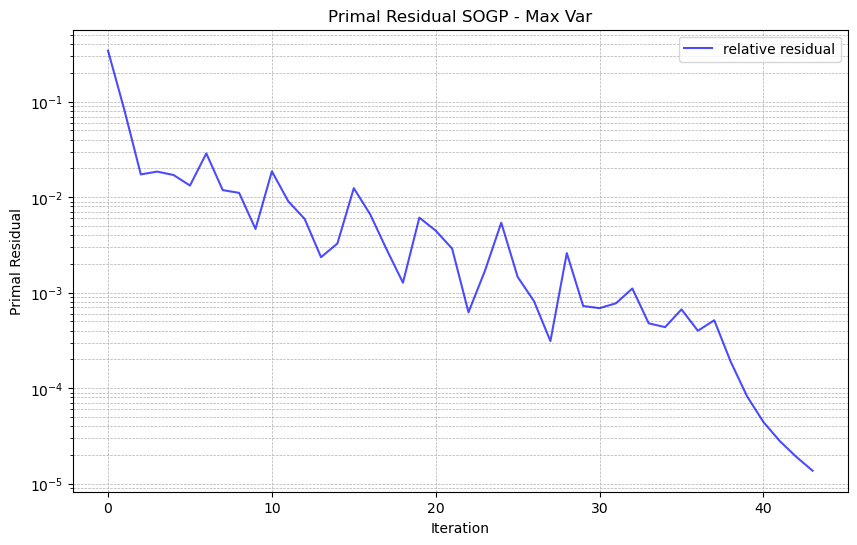

In [122]:
# sogp primal residual

plt.figure(figsize=(10,6))
# plt.scatter(x_axis, log_rel_res, color="blue", alpha=0.7, label="relative residual")
plt.plot(x_axis_sogp, primal_residual_sogp, color="blue", alpha=0.7, label="relative residual")
plt.yscale("log")
plt.title("Primal Residual SOGP - Max Var")
plt.xlabel("Iteration")
plt.ylabel("Primal Residual")
plt.legend()
plt.grid(True, which='both', linestyle="--", linewidth=0.5)
plt.show()


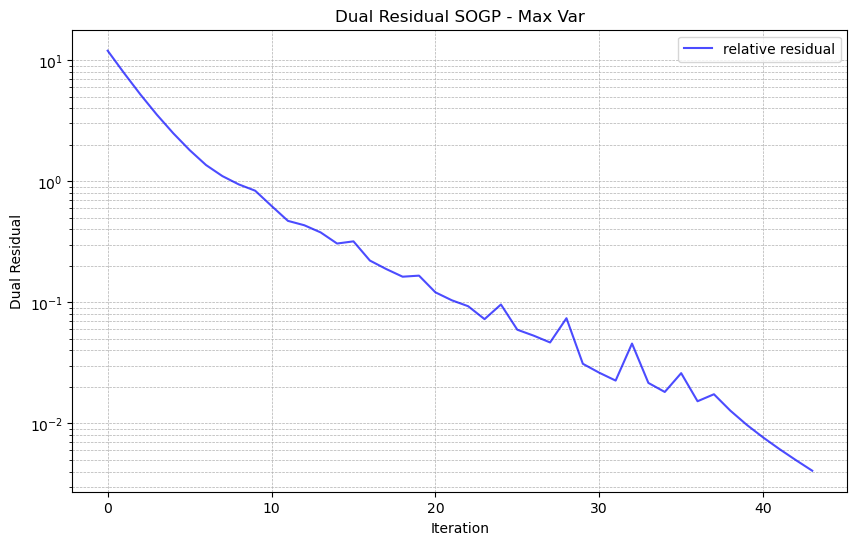

In [123]:
# dual residual

plt.figure(figsize=(10,6))
# plt.scatter(x_axis, log_rel_res, color="blue", alpha=0.7, label="relative residual")
plt.plot(x_axis_sogp, dual_residual_sogp, color="blue", alpha=0.7, label="relative residual")
plt.yscale("log")
plt.title("Dual Residual SOGP - Max Var")
plt.xlabel("Iteration")
plt.ylabel("Dual Residual")
plt.legend()
plt.grid(True, which='both', linestyle="--", linewidth=0.5)
plt.show()

## Compare

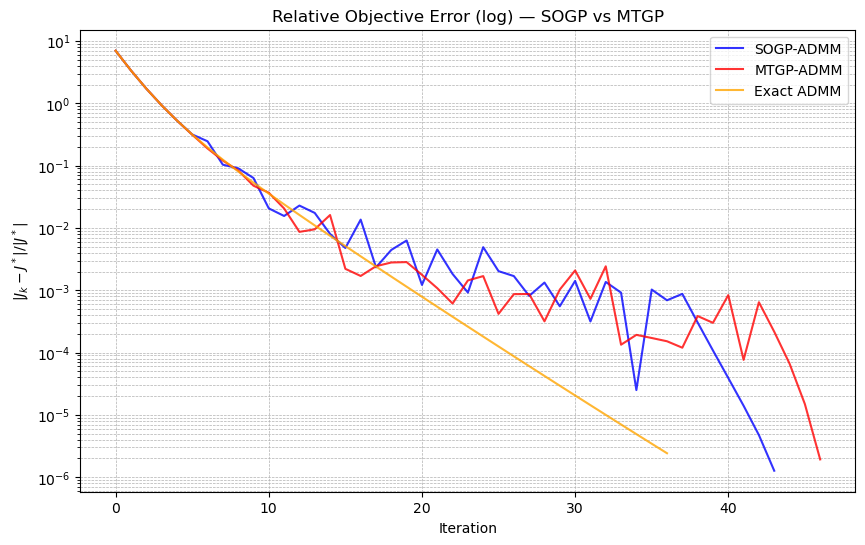

In [124]:
x_axis_sogp = np.arange(len(obj_val_sogp))
x_axis_mtgp = np.arange(len(obj_val_mtgp))
x_axis_vanilla = np.arange(len(obj_val_vanilla))


sogp_rel_err = np.abs(obj_val_sogp - exact_obj) / max(np.abs(exact_obj), 1e-12)
mtgp_rel_err = np.abs(obj_val_mtgp - exact_obj) / max(np.abs(exact_obj), 1e-12)
vanilla_rel_err = np.abs(obj_val_vanilla - exact_obj) / max(np.abs(exact_obj), 1e-12)

plt.figure(figsize=(10,6))
plt.plot(x_axis_sogp, np.maximum(sogp_rel_err, 1e-14), color="blue", alpha=0.8, label="SOGP-ADMM")
plt.plot(x_axis_mtgp, np.maximum(mtgp_rel_err, 1e-14), color="red", alpha=0.8, label="MTGP-ADMM")
plt.plot(x_axis_vanilla, np.maximum(vanilla_rel_err, 1e-14), color="orange", alpha=0.8, label="Exact ADMM")
plt.yscale("log")
plt.title("Relative Objective Error (log) — SOGP vs MTGP")
plt.xlabel("Iteration")
plt.ylabel(r"$|J_k - J^*|/|J^*|$")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

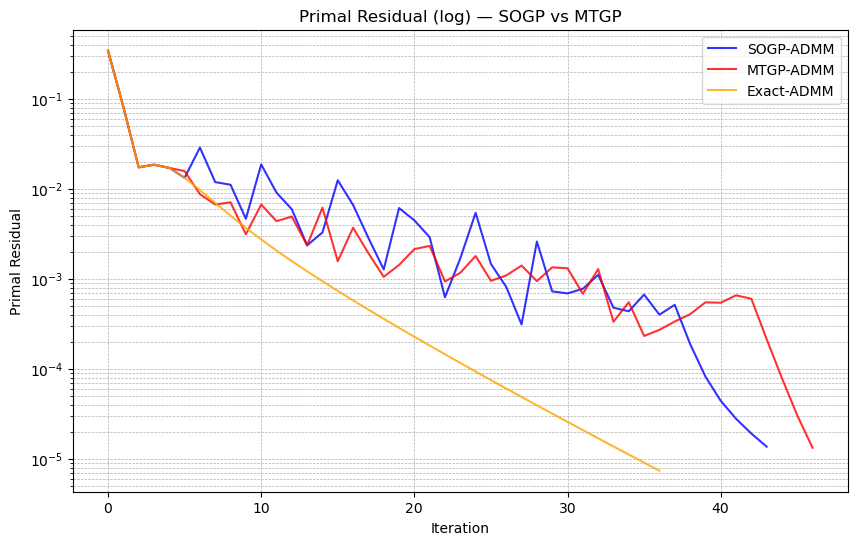

In [125]:
plt.figure(figsize=(10,6))
plt.plot(x_axis_sogp, np.maximum(primal_residual_sogp, 1e-12), color="blue", alpha=0.8, label="SOGP-ADMM")
plt.plot(x_axis_mtgp, np.maximum(primal_residual_mtgp, 1e-12), color="red", alpha=0.8, label="MTGP-ADMM")
plt.plot(x_axis_vanilla, np.maximum(primal_residual_vanilla, 1e-12), color="orange", alpha=0.8, label="Exact-ADMM")
plt.yscale("log")
plt.title("Primal Residual (log) — SOGP vs MTGP")
plt.xlabel("Iteration")
plt.ylabel("Primal Residual")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

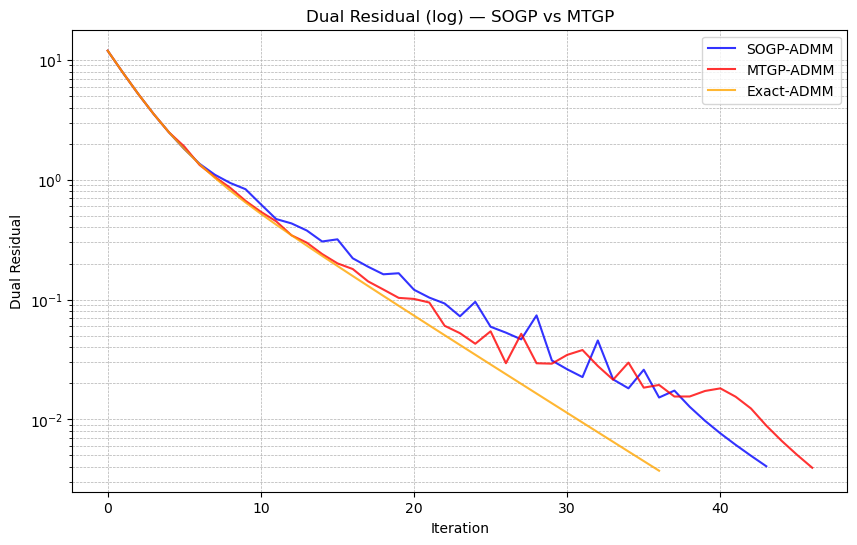

In [126]:
plt.figure(figsize=(10,6))
plt.plot(x_axis_sogp, np.maximum(dual_residual_sogp, 1e-12), color="blue", alpha=0.8, label="SOGP-ADMM")
plt.plot(x_axis_mtgp, np.maximum(dual_residual_mtgp, 1e-12), color="red", alpha=0.8, label="MTGP-ADMM")
plt.plot(x_axis_vanilla, np.maximum(dual_residual_vanilla, 1e-12), color="orange", alpha=0.8, label="Exact-ADMM")
plt.yscale("log")
plt.title("Dual Residual (log) — SOGP vs MTGP")
plt.xlabel("Iteration")
plt.ylabel("Dual Residual")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()


## Analysis variance and psi_k

### Query rate of SOGP

In [127]:
def extract_row_stats(other_stats_row, query_key="do_query"):

    # handleing the fist iteration do not use the GP -> not having stats value
    
    if not isinstance(other_stats_row, list) or len(other_stats_row) == 0:
        return np.nan, np.nan, np.nan, np.nan, 0, 0

    # activte after burn in
    active = [d for d in other_stats_row if isinstance(d, dict) and len(d) > 0]
    if len(active) == 0:
        return np.nan, np.nan, np.nan, np.nan, 0, 0

    # colects each agents var_max 
    var_list = [float(d.get("var_max", np.nan)) for d in active]

    # colect each agent psik
    psi_list = [float(d.get("psi_k", np.nan)) for d in active]

    # colect each agetn query decision
    q_list = [bool(d.get(query_key, False)) for d in active]

    return (
        np.nanmax(var_list),  # get var_max_max at this iteration
        np.nanmean(var_list),  # var_max_mean
        np.nanmean(psi_list),  # psi_k_mean
        np.nanmin(psi_list),  # psi_k_min
        int(np.sum(q_list)),
        q_list
    )

In [128]:
tmp = sogp_data["other_stats"].apply(lambda row: extract_row_stats(row, "do_query"))
sogp_data["var_max_max"] = tmp.apply(lambda x: x[0])
sogp_data["var_max_mean"] = tmp.apply(lambda x: x[1])
sogp_data["psi_k_mean"] = tmp.apply(lambda x: x[2])
sogp_data["psi_k_min"] = tmp.apply(lambda x: x[3])
sogp_data["query_count"] = tmp.apply(lambda x: x[4])

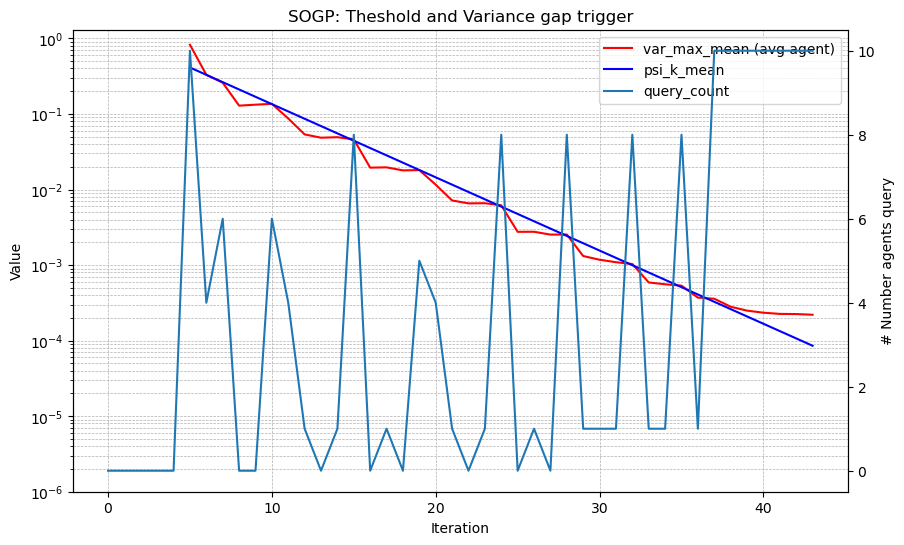

In [141]:
it = sogp_data["iteration"].to_numpy()

fig, ax = plt.subplots(figsize=(10,6))
# ax.plot(it, sogp_data["var_max_max"], color = "red",  label="var_max_max (worst agent)")
ax.plot(it, sogp_data["var_max_mean"], color = "red", label="var_max_mean (avg agent)")
ax.plot(it, sogp_data["psi_k_mean"], color = "blue",label="psi_k_mean")
ax.set_xlabel("Iteration")
ax.set_ylabel("Value")
ax.set_yscale("log")
ax.set_ylim(1e-6, None)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

ax2 = ax.twinx()
ax2.plot(it, sogp_data["query_count"], label="query_count")
ax2.set_ylabel("# Number agents query")
ax2.set_ylim(-0.5, 10.5)

lines = ax.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc="upper right")

plt.title("SOGP: Theshold and Variance gap trigger")
plt.show()


In [130]:
sogp_stats_query_data = tmp.apply(lambda x: x[5])
sogp_stats_query_data[130:150]

Series([], Name: other_stats, dtype: object)

In [131]:
# extract the query per iteration

def extract_query_stats(query_data):
    query_table = []
    for i in range(len(query_data)):
        if query_data[i] == 0:
            pass
        else:
            iter_query = query_data[i]
            query_table.append(iter_query)

    return query_table

query_table = extract_query_stats(sogp_stats_query_data)
# summ through the axis-0
# query_table
query_distr = np.sum(query_table, axis=0)

agent = np.linspace(1, 10, num=10)
agent

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

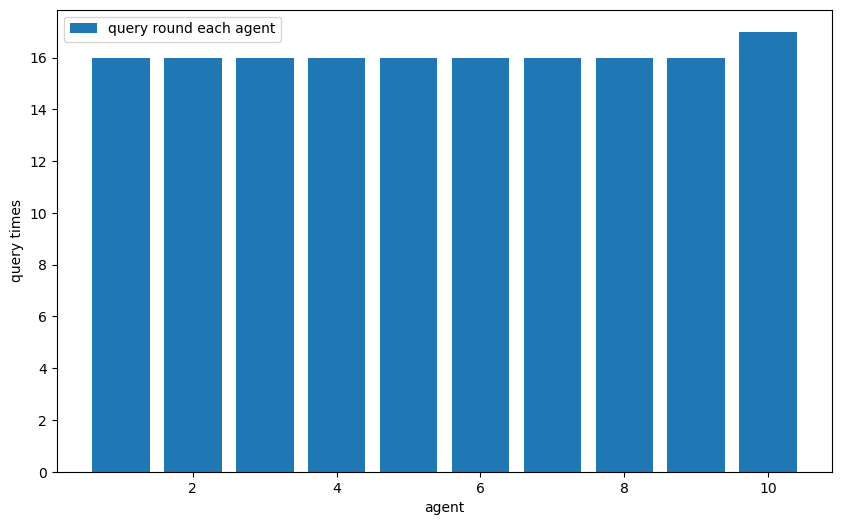

In [132]:
plt.figure(figsize=(10,6))
plt.bar(agent, query_distr, label="query round each agent")
plt.xlabel("agent")
plt.ylabel("query times")
plt.legend()
# plt.grid(True)
plt.show()

In [133]:
prediction_error = sogp_data["grads_error_per_iter"]
(np.array(prediction_error[0]) == 0).all()

np.True_

In [150]:
def plot_grads_error_per_iter(grad_per_iter_data, method):
    prediction_error = grad_per_iter_data["grads_error_per_iter"]
    # len(prediction_error)
    # getting the norm 1 error
    error_per_iter = []
    num_query_iter = 0

    for i in range(len(prediction_error)):
    # print(prediction_error[i])
        if (np.array(prediction_error[i]) == 0).all():
            pass
        else: 
            num_query_iter += 1
            l1_error = np.sum(prediction_error[i])
            error_per_iter.append(l1_error)

    if method == "sogp":    
        # plot the gradient
        plt.figure(figsize=(10,6))
        plt.plot(np.linspace(0, num_query_iter-1, num=num_query_iter), error_per_iter, color="blue", alpha=0.8, label="l1 norm gradient each iter")
        plt.yscale('log')
        plt.title("Gradient trajectory of non-comm iteration - GP-ADMM")
        plt.xlabel("iteration")
        plt.ylabel("l1 norm grad")
        plt.legend()
        plt.grid(True, which="both", linestyle="--", linewidth=0.5)
        plt.show()
        return error_per_iter, num_query_iter

    else:
        plt.figure(figsize=(10,6))
        plt.plot(np.linspace(0, num_query_iter-1, num=num_query_iter), error_per_iter, color="blue", alpha=0.8, label="l1 norm gradient each iter")
        plt.yscale('log')
        plt.title("Gradient trajectory of non-comm iteration - MTGP-ADMM")
        plt.xlabel("iteration")
        plt.ylabel("l1 norm grad")
        plt.legend()
        plt.grid(True, which="both", linestyle="--", linewidth=0.5)
        plt.show()
        return error_per_iter, num_query_iter
    

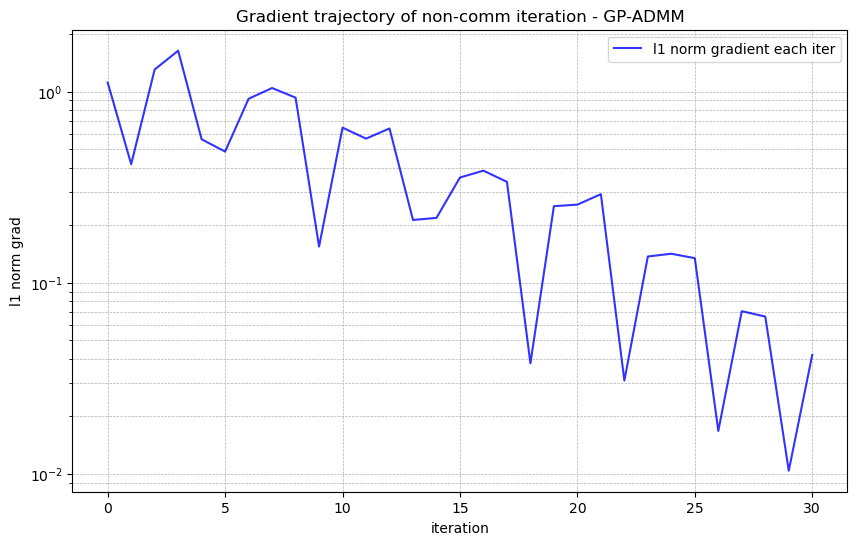

In [151]:
sogp_err_per_iter, sogp_num_com_iter = plot_grads_error_per_iter(sogp_data, "sogp")

## MTGP

In [152]:
tmp = mtgp_data["other_stats"].apply(lambda row: extract_row_stats(row, "do_query"))
mtgp_data["var_max_max"]  = tmp.apply(lambda x: x[0])
mtgp_data["var_max_mean"] = tmp.apply(lambda x: x[1])
mtgp_data["psi_k_mean"]   = tmp.apply(lambda x: x[2])
mtgp_data["psi_k_min"]    = tmp.apply(lambda x: x[3])
mtgp_data["query_count"]  = tmp.apply(lambda x: x[4])

<function matplotlib.pyplot.show(close=None, block=None)>

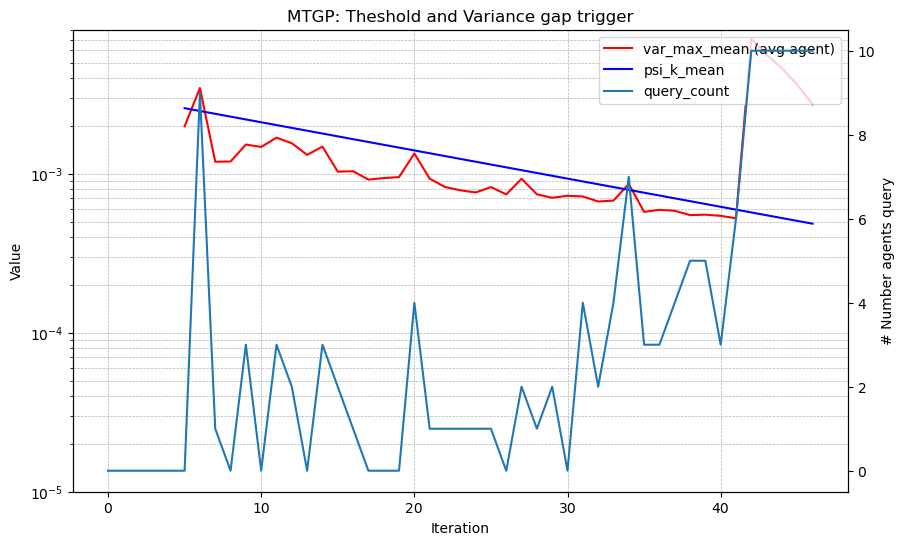

In [153]:
it = mtgp_data["iteration"].to_numpy()

fig, ax = plt.subplots(figsize=(10,6))
# ax.plot(it, mtgp_data["var_max_max"], color = "red",  label="var_max_max (worst agent)")
ax.plot(it, mtgp_data["var_max_mean"], color = "red", label="var_max_mean (avg agent)")
ax.plot(it, mtgp_data["psi_k_mean"], color = "blue",label="psi_k_mean")
ax.set_xlabel("Iteration")
ax.set_ylabel("Value")
ax.set_yscale("log")
ax.set_ylim(1e-5, None)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

ax2 = ax.twinx()
ax2.plot(it, mtgp_data["query_count"], label="query_count")
ax2.set_ylabel("# Number agents query")
ax2.set_ylim(-0.5, 10.5)

lines = ax.get_lines() + ax2.get_lines()

labels = [l.get_label() for l in lines]

ax.legend(lines, labels, loc="upper right")

plt.title("MTGP: Theshold and Variance gap trigger")

plt.show

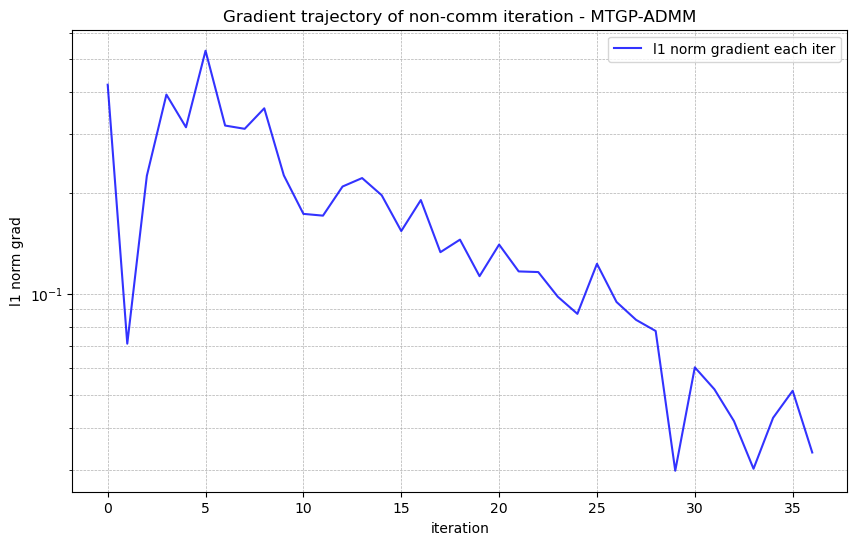

In [154]:
mtgp_err_per_iter, mtgp_num_com_iter = plot_grads_error_per_iter(mtgp_data, "mtgp")

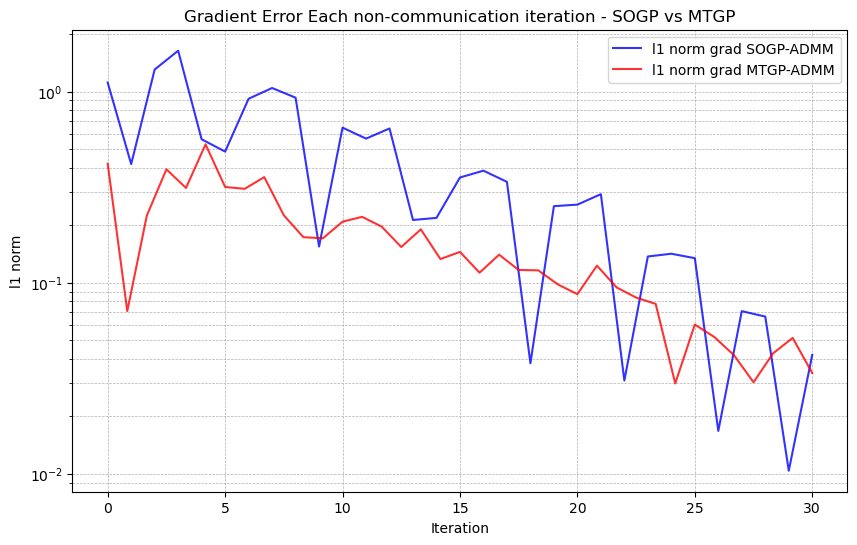

In [155]:
## compcare the gradient grad of the SOGP vs MTGP

plt.figure(figsize=(10,6))
plt.plot(np.linspace(0, num_query_iter-1, num=sogp_num_com_iter), sogp_err_per_iter, color="blue", alpha=0.8, label="l1 norm grad SOGP-ADMM")
plt.plot(np.linspace(0, num_query_iter-1, num=mtgp_num_com_iter), mtgp_err_per_iter, color="red", alpha=0.8, label="l1 norm grad MTGP-ADMM")
plt.yscale("log")
plt.title("Gradient Error Each non-communication iteration - SOGP vs MTGP")
plt.xlabel("Iteration")
plt.ylabel("l1 norm")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()